# Task
Phishing email binary classification using BART-large-MNLI (zero-shot).

Follow the [reference project](https://github.com/salhabheba-cyber/AI-Phishing-Detector) README. Its implementation files were unavailable during preparation; labels and the binary decision rule below are explicit experiment choices, not a verified reproduction.

---


# Prerequisites

Use the Python version in `.python-version` and install dependencies from `requirements.txt`. The first model load downloads weights from Hugging Face.


In [1]:
from pathlib import Path
import re
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from transformers import pipeline
from skimpy import skim

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/backend").is_dir())
DATA_DIR = ROOT / "Training/Phishing_Detection/.data"


c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---

# Dataset
Download the [Kaggle phishing email dataset](https://www.kaggle.com/datasets/naserabdullahalam/phishing-email-dataset) and use the combined `phishing_email.csv` in `Training/Phishing_Detection/.data/`. It contains `text_combined` and binary `label` columns (0 = legitimate, 1 = phishing/spam).


### **Load** the dataset and **summarize**.


In [2]:
# Load and read dataset.
DATA_PATH = DATA_DIR / "phishing_email.csv"
TEXT_COLUMN = "text_combined"
LABEL_COLUMN = "label"
LABEL_MAP = {0: 0, 1: 1}

data = pd.read_csv(DATA_PATH)
assert {TEXT_COLUMN, LABEL_COLUMN} <= set(data.columns), "Expected text_combined and label columns."
assert data[LABEL_COLUMN].dropna().isin(LABEL_MAP).all(), "Expected binary labels 0 and 1."


# Summary.
# skim(data)


### **Drop** missing/blank emails and **deduplicate** samples.
Normalize whitespace while preserving email content. Reject conflicting labels before splitting.


In [3]:
# Drop samples with missing text or labels.
rows_before = len(data)
data_dropped = data.dropna(subset=[TEXT_COLUMN, LABEL_COLUMN]).copy()


# Normalize whitespace and remove blank emails.
data_dropped["text"] = data_dropped[TEXT_COLUMN].astype(str).map(
    lambda text: re.sub(r"\s+", " ", text).strip()
)
data_dropped["label"] = data_dropped[LABEL_COLUMN].map(LABEL_MAP)
data_dropped = data_dropped.loc[data_dropped["text"].ne("")]


# Reject conflicting labels, then deduplicate samples and reset the index.
assert data_dropped.groupby("text")["label"].nunique().max() == 1, "Resolve conflicting labels."
data_dropped = data_dropped.drop_duplicates("text")[["text", "label"]].reset_index(drop=True)
assert set(data_dropped["label"]) == {0, 1}


# Summary.
print(f"Removed {rows_before - len(data_dropped):,} missing, blank, or duplicate samples.")
skim(data_dropped)


Removed 409 missing, blank, or duplicate samples.


TypeError: select_dtypes does not support the class date; pass 'object' to select all object-dtype columns

### Split the dataset into Test, Train, and Eval.
Stratify to preserve class proportions. Test supports experimentation; eval is held out.


In [4]:
# Get the Train split. Hold out a split for Test and Eval.
train, holdout = train_test_split(
    data_dropped, train_size=0.7, random_state=123, stratify=data_dropped["label"]
)


# Get the Test and Eval splits from the holdout split.
test, eval_data = train_test_split(
    holdout, train_size=0.5, random_state=123, stratify=holdout["label"]
)


# Summary.
for name, frame in [("Train", train), ("Test", test), ("Eval", eval_data)]:
    print(f"{name} samples: {len(frame):,} --> {len(frame) / len(data_dropped):.2%}")


Train samples: 57,453 --> 70.00%
Test samples: 12,312 --> 15.00%
Eval samples: 12,312 --> 15.00%


# Preprocessing
The model tokenizer handles encoding. No vocabulary or scaler is fitted. Long emails are truncated to the model input limit.

# Model
Use the reference README’s BART model. Candidate labels below are experiment configuration.

In [5]:
MODEL_ID = "facebook/bart-large-mnli"
classifier = pipeline("zero-shot-classification", model=MODEL_ID, device=0 if torch.cuda.is_available() else -1)
LABELS = ["phishing email", "legitimate email"]

def predict(frame):
    results = classifier(frame["text"].tolist(), candidate_labels=LABELS, truncation=True, batch_size=4)
    return [int(result["labels"][0] == LABELS[0]) for result in results]


c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\User\.cache\huggingface\hub\models--facebook--bart-large-mnli. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\fil

# Training
Zero-shot classification does not train on this dataset. The train partition is reserved for future trainable models. No URL score boost or risk-band threshold is added without verified source behavior.

### Test a small development sample first.

In [6]:
test_sample = test.sample(n=min(20, len(test)), random_state=42)
test_predictions = predict(test_sample)
print(classification_report(test_sample["label"], test_predictions, labels=[0, 1], target_names=["legitimate", "phishing"], zero_division=0))


              precision    recall  f1-score   support

  legitimate       0.50      0.62      0.56         8
    phishing       0.70      0.58      0.64        12

    accuracy                           0.60        20
   macro avg       0.60      0.60      0.60        20
weighted avg       0.62      0.60      0.60        20



# Evaluation
After fixing configuration, evaluate the complete held-out eval split. This may be slow on CPU. Do not tune against these results.

              precision    recall  f1-score   support

  legitimate       0.48      0.69      0.57      5885
    phishing       0.52      0.30      0.38      6427

    accuracy                           0.49     12312
   macro avg       0.50      0.50      0.47     12312
weighted avg       0.50      0.49      0.47     12312



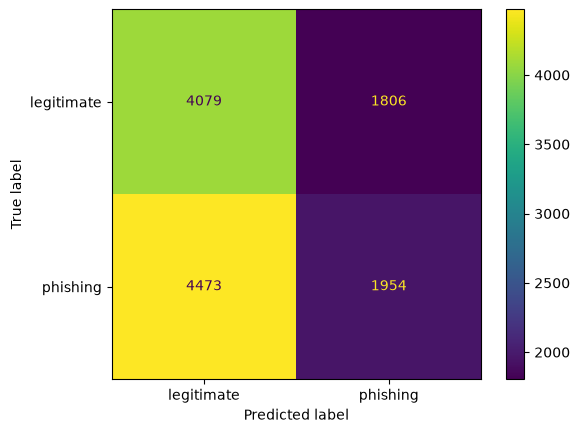

In [7]:
eval_predictions = predict(eval_data)
print(classification_report(eval_data["label"], eval_predictions, labels=[0, 1], target_names=["legitimate", "phishing"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(eval_data["label"], eval_predictions, labels=[0, 1], display_labels=["legitimate", "phishing"])


---

# Token Attribution (Captum)

Explains which words in an email push the zero-shot classifier toward **phishing** or **legitimate**. Run the Model cell first; the full Evaluation run is not required. The explained emails are drawn from the **test** split so the eval split stays held out. This section needs `captum` (`pip install captum`; add it to `requirements.txt`).

How it works:
- The classifier compares two entailment scores, one for `This example is phishing email.` and one for `This example is legitimate email.`. The prediction is phishing when the first score is larger.
- The explained quantity is that **margin** (phishing entailment logit minus legitimate entailment logit). Positive means phishing, so `sigmoid(margin)` equals the pipeline's phishing score.
- **Integrated Gradients** attributes the margin to each email token's embedding, moving from a `<pad>` embedding baseline to the real embedding. The two hypotheses are held fixed.

Attribution is expensive (BART-large, many forward and backward passes per email), so only a few emails are explained and long emails are cut to `MAX_TOKENS` tokens.

### Set up the attribution helpers.

In [7]:
import html

import matplotlib.pyplot as plt
import numpy as np
from captum.attr import IntegratedGradients
from captum.attr import visualization as viz


# Reuse the zero-shot pipeline's NLI model and tokenizer. Keep eval mode, but leave autograd on.
nli_model = classifier.model.eval()
tokenizer = classifier.tokenizer
embedding_layer = nli_model.get_input_embeddings()
entailment_id = classifier.entailment_id
model_device = nli_model.device
HYPOTHESIS_TEMPLATE = 'This example is {}.'  # Pipeline default; the Model cell does not override it.
CLASS_NAMES = {1: 'phishing', 0: 'legitimate'}  # LABELS[0] is phishing, LABELS[1] is legitimate.


# Explanation settings. Lower these if attribution is too slow, raise N_STEPS if the
# convergence delta printed below is large.
N_PER_CLASS = 3          # Emails explained per class.
MAX_TOKENS = 256         # Longer emails are explained on their first MAX_TOKENS tokens only.
N_STEPS = 24             # Integrated Gradients interpolation steps.
INTERNAL_BATCH_SIZE = 4  # Interpolation steps processed at once. Lower it if memory is tight.


# Token IDs for each (email, hypothesis) pair, laid out the way the pipeline's tokenizer does it.
def build_nli_inputs(premise_ids):
    sequences = []
    for label in LABELS:
        hypothesis_ids = tokenizer(HYPOTHESIS_TEMPLATE.format(label), add_special_tokens=False)['input_ids']
        # BART layout: <s> email </s></s> hypothesis </s>. Built by hand because newer
        # tokenizers no longer provide build_inputs_with_special_tokens.
        pair_ids = (
            [tokenizer.bos_token_id] + premise_ids + [tokenizer.eos_token_id] * 2
            + hypothesis_ids + [tokenizer.eos_token_id]
        )
        sequences.append(torch.tensor([pair_ids], device=model_device))
    return sequences


# Margin as a function of the email's token embeddings.
# BartForSequenceClassification cannot take embeddings directly, so run the BART body and the
# classification head here, mirroring its forward pass. Only the email tokens are perturbed.
# The special tokens and the hypothesis stay fixed.
def make_margin_fn(sequences, n_premise):
    constant_embeds = [embedding_layer(ids).detach() for ids in sequences]
    eos_masks = [ids[0].eq(nli_model.config.eos_token_id) for ids in sequences]
    start_token = torch.tensor([[nli_model.config.decoder_start_token_id]], device=model_device)
    start_embed = embedding_layer(start_token).detach()

    def margin_fn(premise_embeds):
        batch = premise_embeds.shape[0]
        entail_logits = []
        for constants, eos_mask in zip(constant_embeds, eos_masks):
            full = torch.cat([
                constants[:, :1].expand(batch, -1, -1),
                premise_embeds,
                constants[:, 1 + n_premise:].expand(batch, -1, -1),
            ], dim=1)

            # The decoder input is the encoder input shifted right by one position.
            decoder_embeds = torch.cat([start_embed.expand(batch, -1, -1), full[:, :-1]], dim=1)
            hidden = nli_model.model(
                inputs_embeds=full, decoder_inputs_embeds=decoder_embeds, use_cache=False,
            )[0]

            # The classification head reads the last <eos> position.
            logits = nli_model.classification_head(hidden[:, eos_mask, :][:, -1, :])
            entail_logits.append(logits[:, entailment_id])
        return entail_logits[0] - entail_logits[1]

    return margin_fn


# Tokenize one email and build everything needed to attribute it.
def prepare_email(text):
    all_ids = tokenizer(text, add_special_tokens=False)['input_ids']
    premise_ids = all_ids[:MAX_TOKENS]
    sequences = build_nli_inputs(premise_ids)
    return {
        'premise_ids': premise_ids,
        'n_total_tokens': len(all_ids),
        'sequences': sequences,
        'margin_fn': make_margin_fn(sequences, len(premise_ids)),
        'premise_embeds': embedding_layer(torch.tensor([premise_ids], device=model_device)).detach(),
    }


# Attribute the margin to each email token. The per-token score is the sum over embedding dimensions.
def explain_email(text):
    prepared = prepare_email(text)
    premise_embeds = prepared['premise_embeds']
    pad_ids = torch.full(premise_embeds.shape[:2], tokenizer.pad_token_id, dtype=torch.long, device=model_device)
    baseline_embeds = embedding_layer(pad_ids).detach()

    attributions, delta = IntegratedGradients(prepared['margin_fn']).attribute(
        premise_embeds,
        baselines=baseline_embeds,
        n_steps=N_STEPS,
        internal_batch_size=INTERNAL_BATCH_SIZE,
        return_convergence_delta=True,
    )
    with torch.no_grad():
        margin = prepared['margin_fn'](premise_embeds).item()

    tokens = tokenizer.convert_ids_to_tokens(prepared['premise_ids'])
    return {
        'tokens': tokens,
        'clean_tokens': [token.lstrip('\u0120').lower() for token in tokens],
        'attributions': attributions.sum(dim=-1)[0].detach().cpu().numpy(),
        'margin': margin,
        'delta': delta.abs().item(),
        'n_total_tokens': prepared['n_total_tokens'],
    }


# Summary.
print(f'Device: {model_device} | entailment logit index: {entailment_id} | labels: {LABELS}')

Device: cpu | entailment logit index: 2 | labels: ['phishing email', 'legitimate email']


### Pick emails and check the attribution wiring.
The margin computed from embeddings must match a normal forward pass of the model.

In [8]:
# Sample the same number of legitimate and phishing emails from the test split.
explain_df = (
    test.groupby('label', group_keys=False)
    .sample(n=N_PER_CLASS, random_state=42)
    .reset_index(drop=True)
)


# Compare the embedding-based margin with the model's own forward pass on the first email.
check = prepare_email(explain_df.loc[0, 'text'])
with torch.no_grad():
    embedding_margin = check['margin_fn'](check['premise_embeds']).item()
    direct_logits = [nli_model(input_ids=ids).logits[0, entailment_id] for ids in check['sequences']]
    direct_margin = (direct_logits[0] - direct_logits[1]).item()

print(f'Margin from embeddings: {embedding_margin:.5f}')
print(f'Margin from model:      {direct_margin:.5f}')


# Confirm the hand-built token layout matches the tokenizer's own pair encoding.
# Only possible when the email was not truncated.
if check['n_total_tokens'] <= MAX_TOKENS:
    for label, ids in zip(LABELS, check['sequences']):
        expected_ids = tokenizer(explain_df.loc[0, 'text'], HYPOTHESIS_TEMPLATE.format(label))['input_ids']
        assert ids[0].tolist() == expected_ids, 'Token layout differs from the pipeline tokenizer.'
    print('Token layout matches the tokenizer.')
else:
    print('Email was truncated, so the token layout comparison was skipped.')
assert abs(embedding_margin - direct_margin) < 1e-3, 'Attribution forward pass does not match the model.'

Margin from embeddings: -1.64371
Margin from model:      -1.64371
Token layout matches the tokenizer.


### Run Integrated Gradients.
This is the slow step. The pipeline score is computed on the full email, so it can differ from the explained score when the email was truncated.

In [11]:
results = []
summary_rows = []
for position, row in explain_df.iterrows():
    result = explain_email(row['text'])
    results.append(result)

    # Pipeline score on the full email for comparison.
    pipeline_scores = classifier(row['text'], candidate_labels=LABELS, truncation=True)
    pipeline_p_phishing = dict(zip(pipeline_scores['labels'], pipeline_scores['scores']))[LABELS[0]]
    summary_rows.append({
        'email': position,
        'true_label': CLASS_NAMES[row['label']],
        'pipeline_p_phishing': pipeline_p_phishing,
        'explained_p_phishing': 1 / (1 + np.exp(-result['margin'])),
        'truncated': result['n_total_tokens'] > MAX_TOKENS,
        'convergence_delta': result['delta'],
    })
    print(f'Explained email {position + 1}/{len(explain_df)}')


# Summary. A large convergence delta means N_STEPS is too low for that email.
print(pd.DataFrame(summary_rows).round(4).to_string(index=False))

Explained email 1/6


KeyboardInterrupt: 

### Visualize the token attributions.
**Green** words push toward phishing and **red** words push toward legitimate. Color strength is relative to the strongest token in each email.

In [ ]:
records = []
for row, result in zip(explain_df.itertuples(), results):
    p_phishing = 1 / (1 + np.exp(-result['margin']))
    predicted = 'phishing' if p_phishing >= 0.5 else 'legitimate'

    # Scale to [-1, 1] for the colors. Escape the tokens because phishing emails often contain HTML.
    scores = result['attributions'] / max(np.abs(result['attributions']).max(), 1e-12)
    records.append(viz.VisualizationDataRecord(
        word_attributions=scores,
        pred_prob=max(p_phishing, 1 - p_phishing),
        pred_class=predicted,
        true_class=CLASS_NAMES[row.label],
        attr_class='phishing margin',
        attr_score=float(result['attributions'].sum()),
        raw_input_ids=[html.escape(token.lstrip('\u0120')) for token in result['tokens']],
        convergence_score=result['delta'],
    ))

_ = viz.visualize_text(records)

NameError: name 'results' is not defined

### Words with the largest total attribution.
Sums each word's attribution over every explained email. With only a few emails this is a rough guide, so raise `N_PER_CLASS` for a steadier ranking.

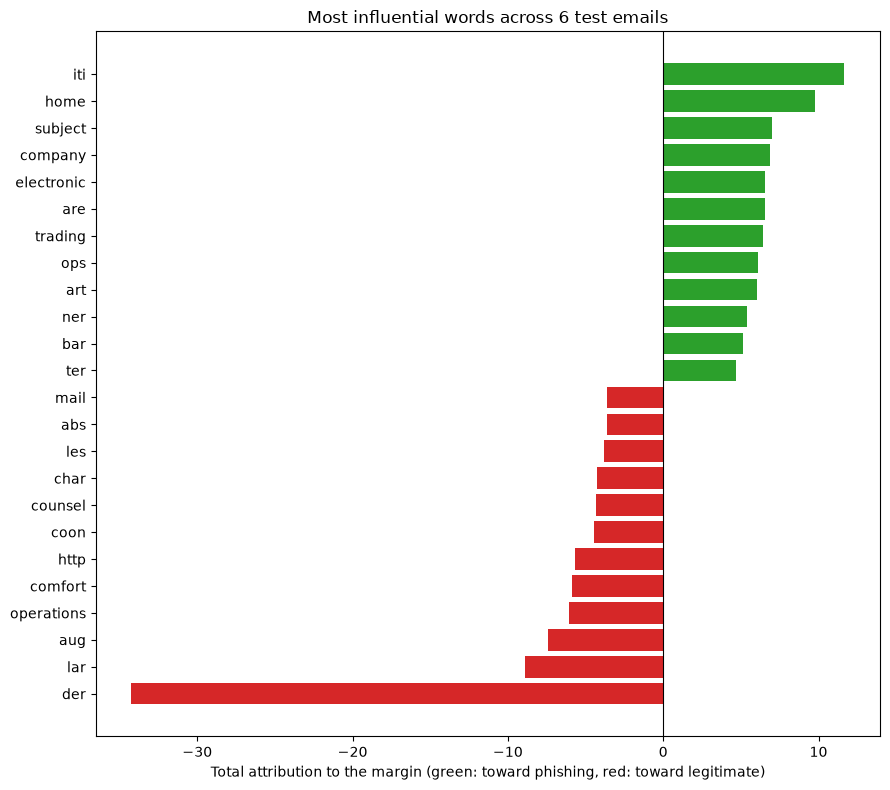

      word  total_attribution  count
       iti          11.663000      1
      home           9.794000      1
   subject           6.995000      1
   company           6.896000      2
electronic           6.585000      4
       are           6.584000      2
   trading           6.401000      6
       ops           6.118000      2
       art           6.058000     12
       ner           5.385000     12
       bar           5.165000      4
       ter           4.716000      5
      mail          -3.590000     12
       abs          -3.595000      1
       les          -3.809000      2
      char          -4.239000      2
   counsel          -4.323000      1
      coon          -4.450000      5
      http          -5.663000     13
   comfort          -5.869000      1
operations          -6.084000      2
       aug          -7.398000      5
       lar          -8.872000      2
       der         -34.240002      1


In [11]:
# Group token attributions by word. Keep alphabetic tokens of three or more letters.
word_scores = {}
for result in results:
    for token, score in zip(result['clean_tokens'], result['attributions']):
        if token.isalpha() and len(token) > 2:
            word_scores.setdefault(token, []).append(score)

word_df = pd.DataFrame({
    'word': list(word_scores),
    'total_attribution': [sum(scores) for scores in word_scores.values()],
    'count': [len(scores) for scores in word_scores.values()],
})


# Take the strongest words in each direction.
toward_phishing = word_df.nlargest(12, 'total_attribution')
toward_legitimate = word_df.nsmallest(12, 'total_attribution')
plot_df = (
    pd.concat([toward_phishing, toward_legitimate])
    .drop_duplicates('word')
    .sort_values('total_attribution')
)


fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(
    plot_df['word'], plot_df['total_attribution'],
    color=np.where(plot_df['total_attribution'] > 0, 'tab:green', 'tab:red'),
)
ax.axvline(0, color='black', linewidth=0.8)
ax.set(
    xlabel='Total attribution to the margin (green: toward phishing, red: toward legitimate)',
    title=f'Most influential words across {len(results)} test emails',
)
fig.tight_layout()
plt.show()


# Summary.
print(plot_df.sort_values('total_attribution', ascending=False).round(3).to_string(index=False))